# VAE 변분 오토인코더 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week15/vae/lab/vae.ipynb)

그림 → 구름 $(\mu, \sigma)$ → 뽑은 점 $z = \mu + \sigma\epsilon$ → 그림. 손실 = 복원 + KL.

- **파트 1**: KL 손 계산 · 재매개변수화
- **파트 2**: 손글씨 숫자로 AE 와 VAE 학습 → 2칸 지도
- **파트 3**: N(0, 1) 에서 뽑아 되살리기 · 지도 격자

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

## 파트 1. KL · 뽑기

칸 하나의 $\text{KL}(N(\mu, \sigma^2) \| N(0, 1)) = \frac12(\mu^2 + \sigma^2 - 1 - \ln\sigma^2)$.

In [ ]:
def kl_to_standard(mu, sigma):
    return None  # TODO: KL of N(mu, sigma^2) from N(0, 1)

for mu, sigma in [(1, 0.5), (0, 1), (0, 2), (2, 1), (0, 0.1)]:
    print(f"mu = {mu}, sigma = {sigma}: KL = {kl_to_standard(mu, sigma):.2f}")

# Reparameterization: the randomness is only in eps, so gradients reach mu and sigma
mu = torch.tensor(1.0, requires_grad=True); sigma = torch.tensor(0.5, requires_grad=True)
eps = torch.tensor(-0.4)
z = None  # TODO: sample z from the cloud using eps
z.backward()
print("z =", round(z.item(), 2), "  dz/dmu =", mu.grad.item(), "  dz/dsigma =", round(sigma.grad.item(), 2))

**예상 결과**

```
mu = 1, sigma = 0.5: KL = 0.82
mu = 0, sigma = 1: KL = 0.00
mu = 0, sigma = 2: KL = 0.81
mu = 2, sigma = 1: KL = 2.00
mu = 0, sigma = 0.1: KL = 1.81
z = 0.8   dz/dmu = 1.0   dz/dsigma = -0.4
```

## 파트 2. AE vs VAE

같은 구조: 인코더 64 → 256 → 2 (AE) 또는 (μ 2, log σ² 2) (VAE), 디코더 2 → 256 → 64.

In [ ]:
digits = load_digits()
X = torch.tensor(digits.data / 16.0, dtype=torch.float32); y = digits.target

def train(X, vae, epochs=400, seed=0):
    torch.manual_seed(seed)
    enc = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 4 if vae else 2))
    dec = nn.Sequential(nn.Linear(2, 256), nn.ReLU(), nn.Linear(256, 64), nn.Sigmoid())
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), 1e-3)
    for ep in range(epochs):
        for idx in torch.randperm(len(X)).split(128):
            x = X[idx]; h = enc(x)
            if vae:
                mu, logvar = h[:, :2], h[:, 2:]
                z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()
                kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum()   # sum of the per-dimension KL
            else:
                z, kl = h, torch.tensor(0.0)
            rec = nn.functional.binary_cross_entropy(dec(z), x, reduction="sum")
            loss = None  # TODO: reconstruction + KL, per image
            opt.zero_grad(); loss.backward(); opt.step()
    return enc, dec

def encode(enc, X):
    with torch.no_grad():
        return enc(X)[:, :2].numpy()                     # the point (AE) or the cloud center mu (VAE)

models = {name: train(X, vae=(name == "VAE")) for name in ["AE", "VAE"]}
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, (enc, dec)) in zip(axs, models.items()):
    M = encode(enc, X)
    ax.scatter(M[:, 0], M[:, 1], c=y, cmap="tab10", s=5)
    ax.add_patch(plt.Circle((0, 0), 2, fill=False, color="red", ls="--"))
    ax.set_title(f"{name}: mean {M.mean(0).round(1)}, std {M.std(0).round(2)}"); ax.set_aspect("equal")
plt.show()

**예상 결과**

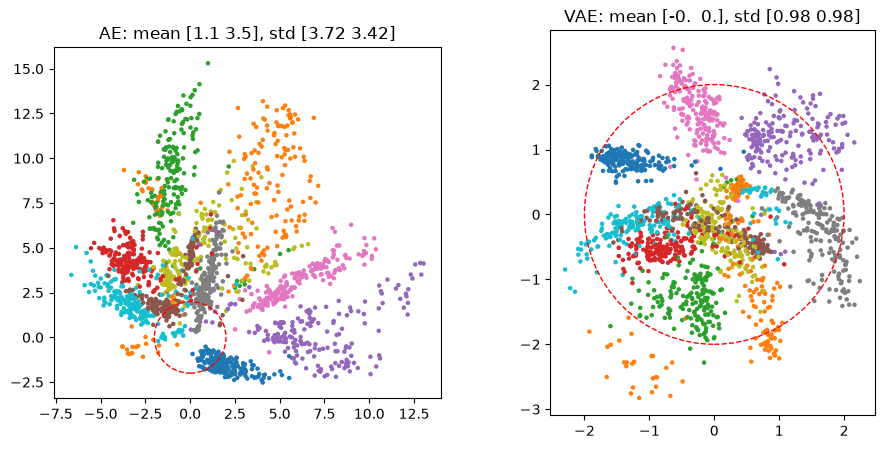

## 파트 3. N(0, 1) 에서 뽑아 되살리기

In [ ]:
clf = LogisticRegression(max_iter=2000).fit(digits.data / 16.0, y)   # judge which digit a picture looks like

torch.manual_seed(2)
z = torch.randn(2000, 2)
for name, (enc, dec) in models.items():
    with torch.no_grad():
        pics = dec(z).numpy()
    hist = np.bincount(clf.predict(pics), minlength=10) / len(pics)
    print(f"{name:3s} digits made from N(0,1):", (hist * 100).round(0), " kinds (>= 2%):", int((hist >= 0.02).sum()))

**예상 결과**

```
AE  digits made from N(0,1): [33.  1.  0.  0.  4.  9.  0. 29.  1. 22.]  kinds (>= 2%): 5
VAE digits made from N(0,1): [ 8. 12. 10. 11. 10.  2. 11. 11. 17.  8.]  kinds (>= 2%): 10
```

In [ ]:
def decode_grid(dec, n=9, lim=2.0):
    g = np.linspace(-lim, lim, n)
    z = torch.tensor([[a, b] for b in g[::-1] for a in g], dtype=torch.float32)
    with torch.no_grad():
        pics = dec(z).numpy().reshape(n, n, 8, 8)
    return pics.transpose(0, 2, 1, 3).reshape(n * 8, n * 8)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, (enc, dec)) in zip(axs, models.items()):
    ax.imshow(decode_grid(dec), cmap="gray_r"); ax.set_title(f"{name}: z in [-2, 2] x [-2, 2]"); ax.axis("off")
plt.show()

**예상 결과**

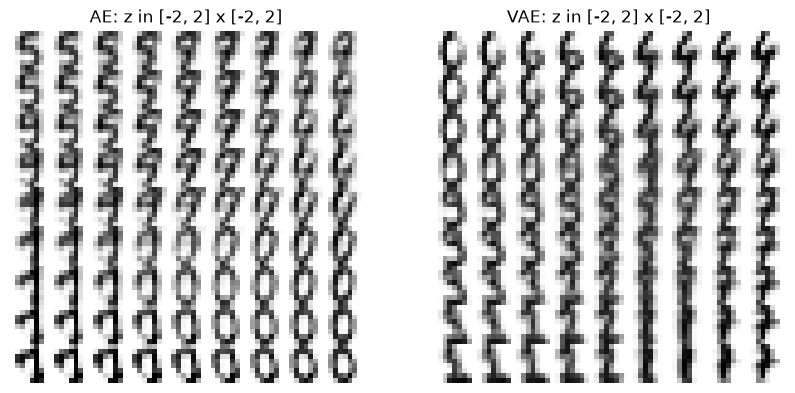

**확인 질문**
1. 파트 1 에서 σ = 0.1 처럼 구름이 아주 작으면 KL 은 왜 커질까?
2. 파트 2 에서 AE 지도의 평균 · 퍼짐은 시드를 바꾸면 어떻게 될까? VAE 는?
3. 파트 3 에서 AE 의 격자 그림은 왜 몇 가지 숫자만 보일까?
4. (도전) VAE 손실의 `kl` 에 0.1 이나 10 을 곱해 다시 학습하면 지도와 그림은 어떻게 바뀌나?